# OVC showcase: downtown Cairo buildings on roads

**Question:** do OpenStreetMap building footprints in downtown Cairo overlap each other, or reach onto the centre-line of a mapped road?

Data: (c) OpenStreetMap contributors, ODbL 1.0, fetched with the Overpass API (see `README.md` in this folder).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'showcase' else Path.cwd()
sys.path.insert(0, str(ROOT))

import geopandas as gpd
import matplotlib.pyplot as plt
from ovc.checks.overlap import OverlapThresholds, find_building_overlaps
from ovc.checks.road_conflict import find_buildings_on_roads
from ovc.core.crs import choose_utm_crs_from_gdf

## 1. Load the data (GeoJSON, EPSG:4326, lon/lat)

In [2]:
data = ROOT / 'showcase' / 'data'
buildings = gpd.read_file(data / 'cairo_downtown_buildings.geojson')
roads = gpd.read_file(data / 'cairo_downtown_roads.geojson')
buildings['bldg_id'] = buildings['osm_id'].astype('int64')
roads['osmid'] = roads['osm_id'].astype('int64')
print(buildings.crs, len(buildings), 'buildings,', len(roads), 'roads')
roads['highway'].value_counts()

EPSG:4326 262 buildings, 163 roads


highway
residential      104
service           34
tertiary          16
tertiary_link      4
secondary          3
primary            2
Name: count, dtype: int64

## 2. Project to the local UTM zone (metres) and run the OVC checks

In [3]:
metric = choose_utm_crs_from_gdf(buildings)
b_m, r_m = buildings.to_crs(metric), roads.to_crs(metric)
print('Metric CRS:', metric)

overlaps = find_building_overlaps(b_m, OverlapThresholds(min_intersection_area_m2=1.0))
conflicts = find_buildings_on_roads(b_m, r_m, road_buffer_m=1.0, min_intersection_area_m2=1.0)
print('Invalid footprints:', int((~b_m.is_valid).sum()))
print('Building-building overlaps:', len(overlaps))
print('Buildings within 1 m of a road centre-line:', conflicts['bldg_id'].nunique())

[INFO] Overlap detection: 262 buildings, vectorized spatial join...


[INFO] Road conflict: 262 buildings, 163 roads, buffer=1.0m


[INFO] Found 9 building-road conflicts


Metric CRS: EPSG:32636
Invalid footprints: 0
Building-building overlaps: 0
Buildings within 1 m of a road centre-line: 9


## 3. Inspect the flagged buildings

In [4]:
names = roads.set_index('osmid')[['name', 'highway']]
table = conflicts.drop(columns='geometry').join(names, on='osmid')
table = table.sort_values('bldg_id').reset_index(drop=True)
table.index = table.index + 1
table['inter_area_m2'] = table['inter_area_m2'].round(1)
table[['bldg_id', 'osmid', 'name', 'highway', 'inter_area_m2']]

,bldg_id,osmid,name,highway,inter_area_m2
1,98246968,908353889,Atafet Moustafa Abou Hif,residential,7.3
2,98246970,28718535,Al Bostan Al Saedi Street,residential,5.6
3,98383698,1428264943,Youssef Al Gendy Street,residential,1.1
4,768636301,28718535,Al Bostan Al Saedi Street,residential,5.2
5,768638897,28718354,Mohamed Mazloum Pasha Street,residential,1.6
6,768977209,28718394,Mohamed Sedki Pasha Street,residential,1.3
7,768977225,908020234,Atafet Al Daramly,residential,7.3
8,1116281358,1292673411,None,service,1.6
9,1501760134,24749268,Kasr El Nil Street,tertiary,10.6


## 4. Map (UTM zone 36N, north up)

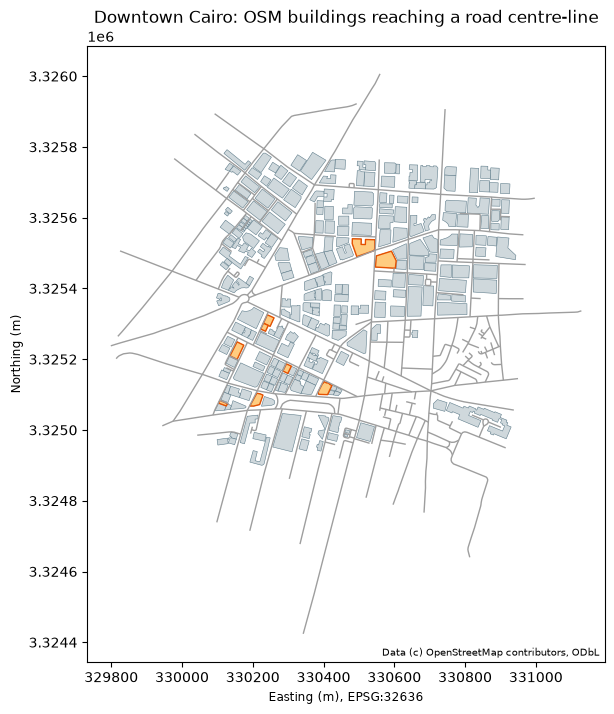

In [5]:
fig, ax = plt.subplots(figsize=(8, 8))
r_m.plot(ax=ax, color='#9e9e9e', linewidth=1)
b_m.plot(ax=ax, facecolor='#cfd8dc', edgecolor='#607d8b', linewidth=0.4)
b_m[b_m['bldg_id'].isin(conflicts['bldg_id'])].plot(
    ax=ax, facecolor='#ffcc80', edgecolor='#e65100')
conflicts.plot(ax=ax, color='#c62828')
ax.set_title('Downtown Cairo: OSM buildings reaching a road centre-line')
ax.set_xlabel(f'Easting (m), {metric}'); ax.set_ylabel('Northing (m)')
ax.text(0.99, 0.01, 'Data (c) OpenStreetMap contributors, ODbL',
        transform=ax.transAxes, ha='right', fontsize=7)
plt.show()